# lambdas: Parameterising REE Profiles in Mantle Xenoliths

Orthogonal polynomial decomposition can be used for dimensional reduction of smooth
function over an independent variable, producing an array of independent values
representing the relative weights for each order of component polynomial. This is an
effective method to parameterise and compare the nature of smooth profiles.

The Rare Earth Element (REE) are a collection of elements with broadly similar physicochemical
properties (the lanthanides), which vary with ionic radii. Given their similar behaviour
and typically smooth function of normalised abundance vs. ionic radii, the REE profiles
and their shapes can be effectively parameterised and dimensionally reduced (14 elements
summarised by 3-4 shape parameters):

$$
\ln([\mathrm{REE}_i]_N)
= \lambda_0
+ \lambda_1 f_1(r_i)
+ \lambda_2 f_2(r_i)
+ \lambda_3 f_3(r_i)
+ \lambda_4 f_4(r_i)
$$

where $[\mathrm{REE}_i]_N$ is the chondrite-normalised abundance of element $i$, $r_i$ is its ionic radius, and $f_n(r_i)$ are predefined orthogonal polynomials (O’Neill 2016; Anenburg 2020, 2022).

Each coefficient represents a different aspect of the REE pattern:  
- **$\lambda_0$**: total enrichment  
- **$\lambda_1$**: slope from light to heavy REE  
- **$\lambda_2$**: curvature  
- **$\lambda_3$**, **$\lambda_4$**: higher-order, fine-scale variations  


Here reduce these REE patterns to lambda values, and visualise the
results.


**Main outputs**
- A clean analysis table (`df_analysis`) containing metadata + REE concentrations.
- A model table (`df_model`) containing λ0–λ4, fit quality (SSE, R², reduced χ²), and **parameter uncertainties** (standard errors derived from the covariance matrix).

**Import packages**


In [18]:
import pyrolite
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyrolite.plot

### Constants: REE ordering, ionic radii, and CI reference composition

This cell defines three “fixed” pieces of information which must be consistent across the full workflow:

- **REE column order (`REE`)**: establishes a single, explicit La→Lu ordering so that arrays and DataFrame slices always align.
- **Ionic radii (`IONIC_RADII`)**: the independent variable $r_i$ used in the orthogonal polynomial basis and for plot spacing.
- **CI reference (`CI`)**: the chondrite (CI) normalising composition used to convert concentrations to a comparable pattern shape.

Others:
$\text{CI-normalised ratio:}\quad (\mathrm{REE}_i)_N = \frac{\mathrm{REE}_i}{\mathrm{CI}_i}
$

$\text{Log-space pattern used for fitting:}\quad y_i = \ln\left(\frac{\mathrm{REE}_i}{\mathrm{CI}_i}\right)
$


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REE = ["La", "Ce", "Pr", "Nd", "Sm", "Eu", "Gd", "Tb", "Dy", "Ho", "Er", "Tm", "Yb", "Lu"]

IONIC_RADII = np.array([
    1.160, 1.143, 1.126, 1.109, 1.079, 1.066,
    1.053, 1.040, 1.027, 1.015, 1.004, 0.994,
    0.985, 0.977
], dtype=float)

CI = np.array([
    0.2472, 0.6308, 0.0950, 0.4793, 0.1542, 0.0592,
    0.2059, 0.0375, 0.2540, 0.0554, 0.1645, 0.0258,
    0.1684, 0.0251
], dtype=float)

## 2. Data cleaning

### Load the spreadsheet a

This cell reads the source spreadsheet and constructs **one** clean analysis table (`df_analysis`) which keeps:

- **Metadata columns** (sample ID, province, temperature, pressure, depth, etc.), and
- **REE concentration columns** (La–Lu),

Key steps:

- **Below detection limit handling**: text values like `"Below LOD"` are converted to `NaN` (missing) so they do not silently propagate as strings.
- **Numeric coercion**: all REE columns and numeric metadata are coerced to numeric types so that maths and plotting behave predictably.
- **Row removal for empty REE patterns**: rows with no REE values at all are dropped


In [24]:
df = pd.read_excel("../MES - Anastasia/Sudholz_2023.xlsx")  # Kimberley
# df = pd.read_excel("../MES - Anastasia/Sudholz_2022.xlsx")  # Gawler

df = df.rename(columns={"SAMPLE NO. ": "SAMPLE NO."})

meta_cols = ["SAMPLE NO.", "PROVINCE", "LOCATION", "REFERENCE", "Temp (Celc)", "GPa", "Depth (km)"]

df_analysis = df[meta_cols + REE].copy()

for col in REE:
    m = df_analysis[col].astype(str).str.strip().eq("Below LOD")
    df_analysis.loc[m, col] = np.nan
    df_analysis[col] = pd.to_numeric(df_analysis[col], errors="coerce")

for col in ["Temp (Celc)", "GPa", "Depth (km)"]:
    if col in df_analysis.columns:
        df_analysis[col] = pd.to_numeric(df_analysis[col], errors="coerce")

df_analysis = df_analysis.dropna(how="all", subset=REE).reset_index(drop=True)

print("df_analysis shape:", df_analysis.shape)
df_analysis.head()

df_analysis shape: (580, 21)


,SAMPLE NO.,PROVINCE,LOCATION,REFERENCE,Temp (Celc),GPa,Depth (km),La,Ce,Pr,...,Sm,Eu,Gd,Tb,Dy,Ho,Er,Tm,Yb,Lu
0,MT.L C5R5 R,WEST KIMBERLEY,CALWYNYARDAH,This Study,1298.763801,7.260286,-222.027082,6.73,23.39,3.79,...,2.77,0.756,1.87,0.185,0.890,0.118,0.236,0.0250,0.111,0.0139
1,MT.L C5R5 C,WEST KIMBERLEY,CALWYNYARDAH,This Study,1293.389547,7.083453,-216.619364,6.73,23.80,3.75,...,2.90,0.755,1.79,0.176,0.903,0.114,0.224,0.0312,0.099,0.0149
2,MT.L C8R1 R,WEST KIMBERLEY,CALWYNYARDAH,This Study,1280.221710,7.036663,-215.188464,6.21,21.04,3.41,...,3.01,0.862,2.06,0.203,1.090,0.131,0.280,0.0222,0.131,0.0170
3,MT.L C3R2 C,WEST KIMBERLEY,CALWYNYARDAH,This Study,1222.453204,6.713247,-205.298088,25.27,85.90,10.96,...,3.63,0.700,1.41,0.124,0.485,0.071,0.139,0.0150,0.078,0.0121
4,MT.L C3R3 C,WEST KIMBERLEY,CALWYNYARDAH,This Study,1260.544196,6.692601,-204.666712,12.08,36.70,5.04,...,2.13,0.429,0.91,0.084,0.373,0.051,0.123,0.0078,NaN,NaN


## 3. Lambda framework (model, uncertainty, and fit statistics)

### Define the orthogonal polynomial basis and the λ fitting routine

This builds the full λ-fit model:

1. **O’Neill (2016) basis functions** $f_n(r_i)$ evaluated at ionic radii.
2. A helper to compute **covariance** and **standard errors** for fitted parameters.
3. A safe transform to $ln(\mathrm{REE}/\mathrm{CI})$ which respects missing values.
4. `lambda_lnREE(...)`: a single function which fits $lambda_0\dots\lambda_4$ and returns both coefficients and diagnostics.

#### Model form

For a given sample, define:

$y_i = \ln\left(\frac{\mathrm{REE}_i}{\mathrm{CI}_i}\right)$

and stack the basis functions into a design matrix $mathbf{F}$ (rows = REEs used in the fit; columns = $f_0\dots f_4$. 

The model is: $\mathbf{y} = \mathbf{F}\,\boldsymbol{\lambda} + \boldsymbol{\varepsilon}$

The ordinary least squares solution is:$\hat{\boldsymbol{\lambda}} = (\mathbf{F}^\mathsf{T}\mathbf{F})^{-1}\,\mathbf{F}^\mathsf{T}\mathbf{y}$

#### Partial fits (missing REEs)

The fit uses only the subset of REEs with finite $y_i$.

- $n_\text{used}$: number of REEs used in the fit.
- $n_\text{params}$: number of λ terms fitted (degree+1).
- $text{dof} = n_\text{used} - n_\text{params}$: degrees of freedom (must be $>0$ for stable uncertainty and reduced-$chi^2$ estimates).

#### Fit quality and uncertainty

Residuals: $mathbf{r} = \mathbf{y} - \mathbf{F}\hat{\boldsymbol{\lambda}}$

Sum of squared errors (SSE): $mathrm{SSE} = \sum r_i^2$

An estimate of residual variance:
$s^2 = \frac{\mathrm{SSE}}{\text{dof}}
$

Parameter covariance matrix: $\mathrm{Cov}(\hat{\boldsymbol{\lambda}}) = s^2\,(\mathbf{F}^\mathsf{T}\mathbf{F})^{-1}$

Standard errors used as **error bars**: $\sigma_{\lambda_j} = \sqrt{\mathrm{Cov}_{jj}}$

Reduced chi-square (“MSWD-style”) uses an assumed constant $sigma$ in ln-space (set by `s_lnREE_percent`): $\chi^2 = \sum \left(\frac{r_i}{\sigma}\right)^2, \qquad \chi^2_\nu = \frac{\chi^2}{\text{dof}}$

Interpreting $chi^2_\nu$: values near 1 indicate misfit comparable to the assumed uncertainty; values $> 1$ indicate poor fit (or underestimated uncertainty).


In [26]:
def oneill_2016_basis(r, degree=4):
    """
    Build design matrix F for O'Neill (2016) orthogonal polynomial terms.
    Columns correspond to f0..f_degree, rows correspond to REEs used in the fit.
    """
    r = np.asarray(r, dtype=float)

    f0 = np.ones_like(r)
    f1 = (r - 1.05477)
    f2 = (r - 1.00533) * (r - 1.12824)
    f3 = (r - 0.99141) * (r - 1.06055) * (r - 1.14552)
    f4 = (r - 0.98482) * (r - 1.03052) * (r - 1.10441) * (r - 1.15343)

    cols = [f0, f1, f2, f3, f4]
    return np.column_stack(cols[: degree + 1])


def _safe_ln_ratio(x, ci):
    """
    Compute ln(x/ci) safely.
    Returns:
      y_all: ln(x/ci) with NaN where invalid
      good: boolean mask where x and ci are finite and x>0 and ci>0
    """
    x = np.asarray(x, float)
    ci = np.asarray(ci, float)
    y = np.full_like(x, np.nan, dtype=float)
    good = np.isfinite(x) & np.isfinite(ci) & (x > 0) & (ci > 0)
    y[good] = np.log(x[good] / ci[good])
    return y, good


def _ols_cov_se(F, y, beta):
    """
    Ordinary least squares covariance + standard errors.
    cov = s^2 * (F^T F)^-1 where s^2 = SSE / dof
    """
    n, p = F.shape
    resid = y - F @ beta
    dof = n - p
    if dof <= 0:
        return None, None, dof, np.nan, resid

    sse = float(np.sum(resid**2))
    s2 = sse / dof

    # Use pseudo-inverse for stability (prevents some blow-ups)
    XtX_inv = np.linalg.pinv(F.T @ F)
    cov = s2 * XtX_inv
    se = np.sqrt(np.diag(cov))
    return cov, se, dof, s2, resid


def fit_lambdas_ols(F, y):
    """
    Stable OLS solve using lstsq + rcond.
    """
    beta, *_ = np.linalg.lstsq(F, y, rcond=1e-12)
    return beta


def lambda_lnREE(
    sample_ppm,
    degree=4,
    exclude=(),
    s_lnREE_percent=2.0,   # "assumed ln uncertainty" (%) for reduced chi^2
    ree_order=REE,
    radii=IONIC_RADII,
    ci=CI,
    min_points=None,       # optional override; default = number of parameters (degree+1)
):
    """
    Partial-fit lambda solver + statistics.

    What it does:
    -------------
    1) compute y_all = ln(REE/CI) for all 14 REE
    2) build a fit mask = valid & not excluded
    3) require enough points to solve lambdas (>= degree+1)
    4) solve lambdas via OLS
    5) compute:
       - SSE, dof
       - reduced chi^2 (MSWD-like) using assumed ln uncertainty
       - R2 and adjusted R2
       - covariance + SE for each lambda
    6) predict full 14-REE fitted curve (ln-space + exp back to ratio-space)
       (exp can overflow if lambdas blow up — we guard that below)
    """
    sample_ppm = np.asarray(sample_ppm, dtype=float)
    radii = np.asarray(radii, dtype=float)
    ci = np.asarray(ci, dtype=float)

    # (A) validity for ln
    y_all, good_all = _safe_ln_ratio(sample_ppm, ci)

    # (B) exclusion mask
    excl_mask = np.ones(len(ree_order), dtype=bool)
    for el in exclude:
        if el in ree_order:
            excl_mask[ree_order.index(el)] = False

    # (C) final points used in regression
    fit_mask = good_all & excl_mask
    rr = radii[fit_mask]
    y = y_all[fit_mask]

    # Need at least as many points as parameters
    p = degree + 1
    if min_points is None:
        min_points = p

    if y.size < min_points:
        raise ValueError(f"Not enough valid REEs for degree={degree}: need >= {min_points}, have {y.size}.")

    # (D) design matrix + fit
    F = oneill_2016_basis(rr, degree=degree)
    lambdas = fit_lambdas_ols(F, y)

    # (E) stats in ln-space (used points)
    y_pred_used = F @ lambdas
    resid_used = y - y_pred_used

    sse = float(np.sum(resid_used**2))
    n = int(y.size)
    dof = int(n - p)

    # R2 + adjusted R2
    y_mean = float(np.mean(y))
    tss = float(np.sum((y - y_mean) ** 2))
    R2 = np.nan if tss == 0 else 1.0 - (sse / tss)
    adj_R2 = np.nan
    if dof > 0 and tss != 0:
        adj_R2 = 1.0 - (1.0 - R2) * (n - 1) / dof

    # Reduced chi^2 / MSWD-like using assumed ln uncertainty
    sigma_ln_assumed = 0.01 * float(s_lnREE_percent)
    chi_sq = float(np.sum((resid_used / sigma_ln_assumed) ** 2))
    red_chi_sq = np.nan if dof <= 0 else chi_sq / dof

    cov, se, dof2, s2, _ = _ols_cov_se(F, y, lambdas)

    # (F) predict full pattern (14 REE)
    F_all = oneill_2016_basis(radii, degree=degree)
    y_pred_all = F_all @ lambdas

    # Guard exp overflow: clip ln values before exp
    # (Prevents RuntimeWarning and keeps ratios finite for plotting)
    y_pred_all_clip = np.clip(y_pred_all, -50, 50)
    pred_ratio_all = np.exp(y_pred_all_clip)

    obs_ratio_all = np.full_like(sample_ppm, np.nan, dtype=float)
    obs_ratio_all[good_all] = sample_ppm[good_all] / ci[good_all]

    MFR_all = np.full_like(sample_ppm, np.nan, dtype=float)
    ok = good_all & np.isfinite(pred_ratio_all) & (pred_ratio_all > 0)
    MFR_all[ok] = obs_ratio_all[ok] / pred_ratio_all[ok]

    return {
        "lambdas": lambdas,
        "cov": cov,
        "se": se,                 # standard errors (error bars)
        "degree": degree,
        "exclude": exclude,

        "fit_mask": fit_mask,     # which REEs were actually used
        "n_used": n,
        "n_params": p,
        "dof": dof,

        "SSE": sse,
        "R2": R2,
        "adj_R2": adj_R2,
        "chi_sq": chi_sq,
        "red_chi_sq": red_chi_sq,

        "y_obs_used": y,
        "y_pred_used": y_pred_used,
        "resid_used": resid_used,

        "y_all": y_all,
        "y_pred_all": y_pred_all,
        "pred_ratio_all": pred_ratio_all,
        "obs_ratio_all": obs_ratio_all,
        "MFR_all": MFR_all,
    }

## 4. Fit lambdas across the dataset

### Batch fitting and building the model table (`df_model`)

This cell runs `lambda_lnREE(...)` for every row in `df_analysis` and records:

- λ coefficients (**λ0–λ4**),
- parameter uncertainties (**λ0_σ–λ4_σ**),
- fit-quality metrics (**SSE, R², adjusted R², χ², reduced χ²**),
- fit support (**n_used, dof**).

The results are stored in `df_lambdas` and then **joined back** to the original metadata table to form `df_model`. This join strategy:
- preserves the original metadata without creating duplicate columns, and
- keeps one row per sample with all model outputs attached for plotting/statistics.


In [28]:
records = []
failed = 0

for i, row in df_analysis.iterrows():
    sample = row[REE].to_numpy(dtype=float)

    try:
        out = lambda_lnREE(sample, degree=4, exclude=(), s_lnREE_percent=2.0)  # keep Eu in
        rec = {
            "row_id": i,
            "λ0": out["lambdas"][0],
            "λ1": out["lambdas"][1],
            "λ2": out["lambdas"][2],
            "λ3": out["lambdas"][3],
            "λ4": out["lambdas"][4],
            "λ0_σ": out["se"][0] if out["se"] is not None else np.nan,
            "λ1_σ": out["se"][1] if out["se"] is not None else np.nan,
            "λ2_σ": out["se"][2] if out["se"] is not None else np.nan,
            "λ3_σ": out["se"][3] if out["se"] is not None else np.nan,
            "λ4_σ": out["se"][4] if out["se"] is not None else np.nan,
            "SSE": out["SSE"],
            "R2": out["R2"],
            "adj_R2": out["adj_R2"],
            "chi_sq": out["chi_sq"],
            "red_chi_sq": out["red_chi_sq"],
            "n_used": out["n_used"],
            "dof": out["dof"],
        }
        records.append(rec)

    except Exception:
        failed += 1

df_lambdas = pd.DataFrame(records).set_index("row_id").sort_index()

# Join ONLY new columns back to df_analysis 
df_model = df_analysis.join(df_lambdas, how="inner")

print("Total rows in df_analysis:", len(df_analysis))
print("Rows with successful lambda fits:", len(df_model))
print("Rows failed:", failed)

# Quick sanity checks
print("\nDistribution of n_used (how many REEs used per fit):")
display(df_model["n_used"].describe())

print("\nHow many rows have all 5 lambdas finite?")
print(np.isfinite(df_model[["λ0","λ1","λ2","λ3","λ4"]].to_numpy()).all(axis=1).sum())

Total rows in df_analysis: 580
Rows with successful lambda fits: 580
Rows failed: 0

Distribution of n_used (how many REEs used per fit):


count    580.000000
mean      12.739655
std        1.846290
min        5.000000
25%       12.000000
50%       14.000000
75%       14.000000
max       14.000000
Name: n_used, dtype: float64


How many rows have all 5 lambdas finite?
580


**Columns**
- **λ0–λ4**: fitted coefficients describing enrichment, slope, curvature, and higher-order shape.
- **λ*_σ**: 1σ standard errors for each coefficient (from the parameter covariance).
- **n_used / dof**: support for each fit (how many REEs contributed; whether statistics are defined).
- **red_chi_sq**: misfit relative to the assumed ln-space uncertainty.

Downstream interpretation generally uses a filtered subset (created later) to avoid unstable fits.


## 5. Exploratory view of CI-normalised REE patterns

### Plot all CI-normalised patterns (ratio-space)

Before interpreting λ-space, it is useful to visually check the **raw** CI-normalised patterns:

- Plotting **REE/CI** (not ln) retains the “spider diagram” appearance.
- Using a **log y-axis** makes relative enrichments comparable across a wide dynamic range.
- Using **ionic radius spacing** and **inverting the x-axis** reproduces the standard LREE→HREE left-to-right convention while keeping physical spacing.


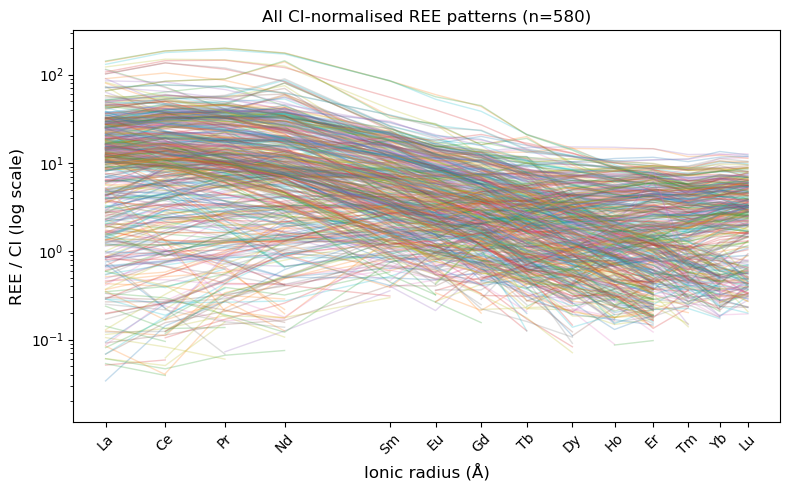

In [30]:
r = IONIC_RADII
ci = CI

plt.figure(figsize=(8, 5))

n_plotted = 0
for _, row in df_analysis.iterrows():
    x = row[REE].to_numpy(dtype=float)
    y_all, good = _safe_ln_ratio(x, ci)  # ln(REE/CI)
    if not np.any(good):
        continue

    # Plot ratio-space (REE/CI) with log y-axis
    ratio = np.full_like(x, np.nan, dtype=float)
    ratio[good] = x[good] / ci[good]
    plt.plot(r, ratio, alpha=0.25)

    n_plotted += 1

plt.yscale("log")
plt.gca().invert_xaxis()
plt.xticks(r, REE, rotation=45)
plt.xlabel("Ionic radius (Å)")
plt.ylabel("REE / CI (log scale)")
plt.title(f"All CI-normalised REE patterns (n={n_plotted})")
plt.tight_layout()
plt.show()


#### What this plot shows:
- Every sample’s CI-normalised REE pattern (REE/CI).
- X-axis spacing is ionic radius (so LREE are more spread out than HREE).
- Log y-axis lets you compare shapes even when absolute abundances vary a lot.

### Quick dataset sanity checks

- total rows successfully fitted,
- rows with finite λ0–λ4,
- availability of temperature values (if present).


In [22]:
print("df_model rows:", len(df_model))

# how many rows have finite lambdas?
finite_lams = np.isfinite(df_model[["λ0","λ1","λ2","λ3","λ4"]].to_numpy()).all(axis=1)
print("rows with all 5 lambdas finite:", finite_lams.sum())

# temperature availability
if "Temp (Celc)" in df_model.columns:
    temp_ok = np.isfinite(df_model["Temp (Celc)"].to_numpy(float))
    print("rows with finite Temp:", temp_ok.sum())
    print("rows with finite Temp AND finite lambdas:", (temp_ok & finite_lams).sum())
else:
    print("Temp (Celc) column not in df_model")

df_model rows: 580
rows with all 5 lambdas finite: 580
rows with finite Temp: 548
rows with finite Temp AND finite lambdas: 548


## 6. Diagnostics and model behaviour

fit example, fit-quality distribution, degree sensitivity, and λ-space with uncertainty

- **Fit example (ln-space)**: compares observed $ln(\mathrm{REE}/\mathrm{CI})$ against the model prediction for one randomly chosen sample.
- **Reduced χ² distribution**: summarises fit quality across the dataset using $chi^2_\nu$.
- **Degree sensitivity**: tests whether using fewer/more polynomial terms changes fit quality for the same sample.
- **λ-space scatter plots**: shows how samples distribute in λ-space, optionally coloured by temperature, with **standard-error bars** plotted for a subset to avoid clutter.

Important stability step:
- fits with **dof ≤ 0** are removed because reduced χ² and covariance-based uncertainties are undefined or unstable when the number of data points equals the number of fitted parameters.


df_model rows: 580
df_plot rows (after dropping unstable fits): 579


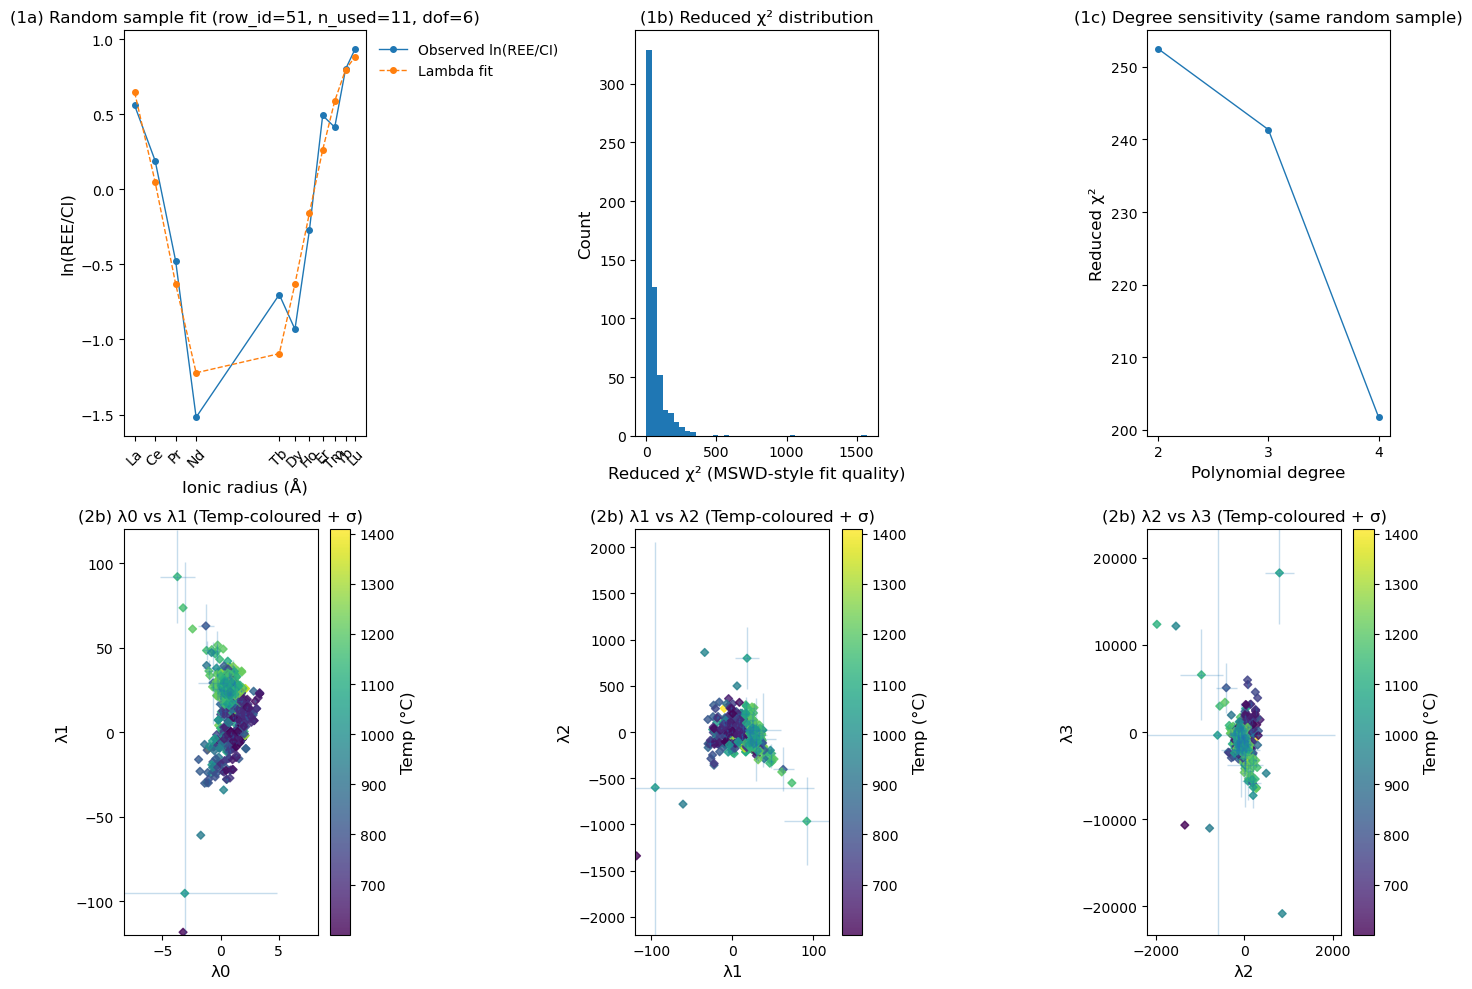

In [33]:
# The *real* condition is dof > 0, not just "finite lambdas".
# If n_used == n_params (e.g., 5 points for 5 lambdas), dof=0 -> red_chi_sq undefined, fit unstable.
# Also explicitly drop row 162 since it is a big outlier.
bad_ids = {162}

df_plot = df_model.copy()

# Drop explicit bad row(s) if present
df_plot = df_plot.drop(index=[i for i in bad_ids if i in df_plot.index], errors="ignore")

# Drop any rows where dof is missing or <= 0 (unstable / undefined reduced χ²)
if "dof" in df_plot.columns:
    df_plot = df_plot[pd.to_numeric(df_plot["dof"], errors="coerce") > 0].copy()

# Also drop rows with non-finite lambdas (safety)
lam_cols = ["λ0","λ1","λ2","λ3","λ4"]
df_plot = df_plot[np.isfinite(df_plot[lam_cols].to_numpy(float)).all(axis=1)].copy()

print("df_model rows:", len(df_model))
print("df_plot rows (after dropping unstable fits):", len(df_plot))

# -------------------------
# 6.1) Random sample selection (from df_plot only)
# -------------------------
rng = np.random.default_rng(42)
rand_row_id = rng.choice(df_plot.index.to_numpy())
rand_sample = df_plot.loc[rand_row_id, REE].to_numpy(dtype=float)

out_rand = lambda_lnREE(rand_sample, degree=4, exclude=(), s_lnREE_percent=2.0)

# Degree sensitivity on same sample
deg_list = [2, 3, 4]
deg_redchi = []
for d in deg_list:
    o = lambda_lnREE(rand_sample, degree=d, exclude=(), s_lnREE_percent=2.0)
    deg_redchi.append(o["red_chi_sq"])

# -------------------------
# 6.2) Temperature array for colouring
# -------------------------
temp = df_plot["Temp (Celc)"].to_numpy(dtype=float) if "Temp (Celc)" in df_plot.columns else None
temp_ok = np.isfinite(temp) if temp is not None else None

# -------------------------
# 6.3) Robust axis helper (prevents one outlier from flattening everything)
# -------------------------
def centred_limits(x, lo=0.01, hi=0.99, centre=0.0):
    """
    Compute symmetric axis limits centred around `centre`
    using robust percentiles to ignore extreme outliers.
    """
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]

    if x.size == 0:
        return (-1, 1)

    q_lo, q_hi = np.quantile(x, [lo, hi])

    span = max(abs(q_lo - centre), abs(q_hi - centre))
    return (centre - span, centre + span)

# -------------------------
# 6.4) Create the 2x3 diagnostics panel
# -------------------------
fig = plt.figure(figsize=(14, 10))

# (1a) observed vs fit (ln space)
ax1 = plt.subplot2grid((2, 3), (0, 0))
fit_mask = out_rand["fit_mask"]
ax1.plot(IONIC_RADII[fit_mask], out_rand["y_obs_used"], marker="o", label="Observed ln(REE/CI)")
ax1.plot(IONIC_RADII[fit_mask], out_rand["y_pred_used"], marker="o", linestyle="--", label="Lambda fit")
ax1.invert_xaxis()
ax1.set_xticks(IONIC_RADII[fit_mask])
ax1.set_xticklabels([e for e, m in zip(REE, fit_mask) if m], rotation=45)
ax1.set_xlabel("Ionic radius (Å)")
ax1.set_ylabel("ln(REE/CI)")
ax1.set_title(f"(1a) Random sample fit (row_id={rand_row_id}, n_used={out_rand['n_used']}, dof={out_rand['dof']})")
ax1.legend()

# (1b) reduced chi^2 distribution
ax2 = plt.subplot2grid((2, 3), (0, 1))
vals = pd.to_numeric(df_plot["red_chi_sq"], errors="coerce").to_numpy(float) if "red_chi_sq" in df_plot.columns else np.array([])
vals = vals[np.isfinite(vals)]
ax2.hist(vals, bins=40)
ax2.set_xlabel("Reduced χ² (MSWD-style fit quality)")
ax2.set_ylabel("Count")
ax2.set_title("(1b) Reduced χ² distribution")

# (1c) degree sensitivity (same sample)
ax3 = plt.subplot2grid((2, 3), (0, 2))
ax3.plot(deg_list, deg_redchi, marker="o")
ax3.set_xticks(deg_list)
ax3.set_xlabel("Polynomial degree")
ax3.set_ylabel("Reduced χ²")
ax3.set_title("(1c) Degree sensitivity (same random sample)")

# -------------------------
# 6.5) Lambda-space plots (2b) with Temp colouring + error bars
# -------------------------
# To keep the plot readable, we draw error bars for a random subset (e.g., 150 points).
# Otherwise 500+ errorbars becomes visual clutter.
n_err = min(150, len(df_plot))
err_ids = rng.choice(df_plot.index.to_numpy(), size=n_err, replace=False)

def scatter_with_temp_and_errorbars(ax, xcol, ycol, xerrcol, yerrcol, title):
    # colour by temp if available, otherwise plain scatter
    if temp is not None:
        sc = ax.scatter(df_plot.loc[temp_ok, xcol], df_plot.loc[temp_ok, ycol],
                        c=temp[temp_ok], alpha=0.8)
        plt.colorbar(sc, ax=ax, label="Temp (°C)")
    else:
        ax.scatter(df_plot[xcol], df_plot[ycol], alpha=0.8)

    # error bars only for subset (readability)
    if (xerrcol in df_plot.columns) and (yerrcol in df_plot.columns):
        x = df_plot.loc[err_ids, xcol].to_numpy(float)
        y = df_plot.loc[err_ids, ycol].to_numpy(float)
        xe = pd.to_numeric(df_plot.loc[err_ids, xerrcol], errors="coerce").to_numpy(float)
        ye = pd.to_numeric(df_plot.loc[err_ids, yerrcol], errors="coerce").to_numpy(float)

        ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(xe) & np.isfinite(ye)
        ax.errorbar(x[ok], y[ok], xerr=xe[ok], yerr=ye[ok], fmt="none", alpha=0.25)

    # robust limits so one point can't crush the cloud
    ax.set_xlim(centred_limits(df_plot[xcol]))
    ax.set_ylim(centred_limits(df_plot[ycol]))

    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.set_title(title)

ax4 = plt.subplot2grid((2, 3), (1, 0))
scatter_with_temp_and_errorbars(ax4, "λ0", "λ1", "λ0_σ", "λ1_σ", "(2b) λ0 vs λ1 (Temp-coloured + σ)")

ax5 = plt.subplot2grid((2, 3), (1, 1))
scatter_with_temp_and_errorbars(ax5, "λ1", "λ2", "λ1_σ", "λ2_σ", "(2b) λ1 vs λ2 (Temp-coloured + σ)")

ax6 = plt.subplot2grid((2, 3), (1, 2))
scatter_with_temp_and_errorbars(ax6, "λ2", "λ3", "λ2_σ", "λ3_σ", "(2b) λ2 vs λ3 (Temp-coloured + σ)")

plt.tight_layout()
plt.show()

#### Interpreting the diagnostics panel

**(1a) Observed vs fit (ln-space)**  
A close match indicates the polynomial basis captures the dominant REE-shape. Systematic deviations highlight structure not represented by the chosen degree (e.g., sharp anomalies or fine-scale curvature).

**(1b) Reduced χ² distribution**  
- $chi^2_\nu \approx 1$: residuals are consistent with the assumed uncertainty.  
- $chi^2_\nu \gg 1$: poor fit (or underestimated uncertainty).  
- $chi^2_\nu \ll 1$: uncertainty likely overestimated, or the model is over-flexible relative to noise.

**(1c) Degree sensitivity**  
If increasing degree yields only marginal improvement, the simpler model may be preferred. If the curve drops strongly with degree, higher-order terms may be necessary to capture real structure (but with increased sensitivity to missing data).

**(2b) λ-space with temperature and error bars**  
Clusters or trends suggest coherent pattern families in the dataset. Temperature gradients (if present) indicate systematic variation with thermodynamic state. Error bars provide a visual cue for which parts of λ-space are well constrained.


## 7. Filtering and outlier control

### Flag unstable fits before interpreting structure

Even with careful fitting, some samples produce unstable λ estimates (often due to too few usable REEs or very poor model agreement).

This cell applies simple, interpretable filters:
- require a minimum number of REEs contributing to the fit (`min_n_used`),
- remove extreme misfits based on reduced χ² (`max_redchi`).

The filtered table (`df_model_filt`) is used for correlation and density analyses so that a handful of unstable solutions do not dominate trends.


In [35]:
# Typical reasons for a crazy outlier:
# - very small n_used (barely enough REEs to solve 5 parameters)
# - very large reduced chi^2 (fit is poor)
# - huge standard errors (fit is unstable)

# You can tune these thresholds:
min_n_used = 10          # require at least 10 REEs contributing
max_redchi = 50          # require fit quality not totally insane

mask_good = (df_model["n_used"] >= min_n_used) & np.isfinite(df_model["red_chi_sq"]) & (df_model["red_chi_sq"] < max_redchi)

print("Rows before filtering:", len(df_model))
print("Rows after filtering:", mask_good.sum())

df_model_filt = df_model.loc[mask_good].copy()

# Show the worst offenders (by |λ1| for example)
worst = df_model.sort_values(by="λ1", key=lambda s: s.abs(), ascending=False).head(10)
display(worst[["SAMPLE NO.", "n_used", "red_chi_sq", "λ0","λ1","λ2","λ3","λ4","λ0_σ","λ1_σ","λ2_σ","λ3_σ","λ4_σ"]])

Rows before filtering: 580
Rows after filtering: 340


,SAMPLE NO.,n_used,red_chi_sq,λ0,λ1,λ2,λ3,λ4,λ0_σ,λ1_σ,λ2_σ,λ3_σ,λ4_σ
162,MT. W C1R2 C,5,NaN,662.035099,15867.899349,192508.633977,1.474752e+06,4.957079e+06,NaN,NaN,NaN,NaN,NaN
209,MT. W C4R1 C,6,105.853759,-249.769588,-6026.015135,-74360.082742,-5.973985e+05,-2.161203e+06,249.415374,6039.722579,75722.652164,621051.924541,2.328808e+06
176,MT. W C2R2 C,6,27.064109,-116.354619,-2797.242691,-34188.439128,-2.723933e+05,-9.842839e+05,126.115059,3053.941525,38288.604946,314030.360928,1.177544e+06
63,MT.L C5R6 C,6,13.901551,-54.848925,-1295.040091,-14528.818729,-1.005736e+05,-2.908766e+05,90.386112,2188.746549,27441.275892,225064.187760,8.439410e+05
74,MT.L C5R6 R,7,3.014735,40.542424,987.892383,13028.605732,1.067840e+05,3.576557e+05,11.810574,289.662327,3769.441236,33106.134976,1.375151e+05
255,MT.AA9 C1R4 R,6,15.258333,-38.181185,-887.408986,-10451.141842,-7.734453e+04,-2.467676e+05,94.694253,2293.070413,28749.229957,235791.590541,8.841664e+05
265,MT.AA9 C7R2 R,8,24.279035,-18.465837,-477.728872,-6099.542130,-5.628992e+04,-2.649311e+05,11.416500,283.608405,3836.936190,36237.998971,1.686062e+05
572,MT.D C2R6 C,6,5.525910,-12.668473,241.041298,-2980.467403,2.465547e+04,-1.683759e+05,2.759977,47.835462,732.530274,6667.800349,3.679249e+04
577,MT.D C2R6 R,6,2.054831,-6.860843,142.519277,-1540.878954,1.216166e+04,-1.059439e+05,1.683029,29.169978,446.695643,4066.012652,2.243599e+04
99,MT. C C2R2 C,8,40.704464,-7.116298,140.993228,-1970.700856,1.236366e+04,-4.144422e+04,1.362593,24.769612,428.907348,4673.343508,3.672511e+04


## 8. Statistics and covariance in λ-space

### Correlation heatmap between λ terms

This cell computes the Pearson correlation matrix across λ0–λ4 (after filtering) and displays it as a heatmap.
- In an ideal orthogonal-basis scenario with consistent data coverage, λ terms would be close to independent.
- In practice, **missing REEs**, varying noise, and real geological structure can introduce correlations.
- Strong correlations indicate **covariance** in parameter space and help interpret which combinations of λ terms vary together.

Correlation is a scaled version of covariance:

$$
\mathrm{Corr}(\lambda_i,\lambda_j) = \frac{\mathrm{Cov}(\lambda_i,\lambda_j)}{\sigma_{\lambda_i}\,\sigma_{\lambda_j}}
$$

This is complementary to the **per-sample** covariance matrices returned during fitting: here the correlation is computed **across samples**.


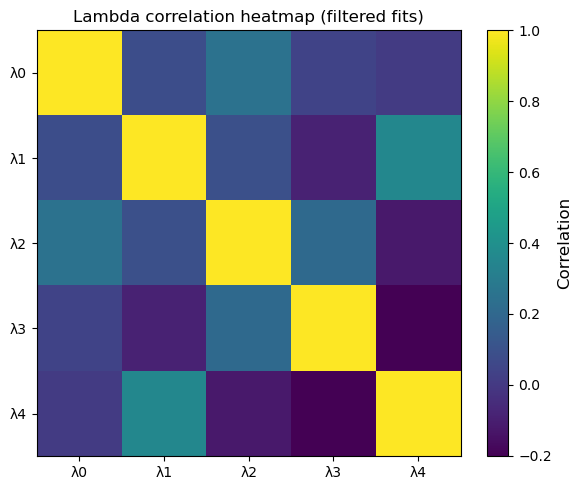

In [36]:
lam_cols = ["λ0","λ1","λ2","λ3","λ4"]
corr = df_model_filt[lam_cols].corr()

plt.figure(figsize=(6, 5))
plt.imshow(corr.to_numpy(), aspect="auto")
plt.xticks(range(len(lam_cols)), lam_cols)
plt.yticks(range(len(lam_cols)), lam_cols)
plt.colorbar(label="Correlation")
plt.title("Lambda correlation heatmap (filtered fits)")
plt.tight_layout()
plt.show()


#### Interpreting the correlation heatmap

- Values near **0** indicate weak linear association between λ terms across samples.
- Strong **positive** correlation indicates two terms rise/fall together (shared trend).
- Strong **negative** correlation indicates trade-offs (one increases as the other decreases).

Correlations can arise from:
- real geological coupling (e.g., processes that change slope and curvature together), and/or
- methodological effects (e.g., missing REEs forcing the fit to trade off coefficients).


### 2D density structure in λ-space (histogram-based)

This cell visualises where samples cluster in λ-space using 2D density histograms for selected λ pairs.
- density reveals the “typical” region of parameter space even when scatter points overlap,
- elongated density clouds indicate covariance and continuous trends,
- multiple peaks can suggest distinct geochemical populations or process end-members.


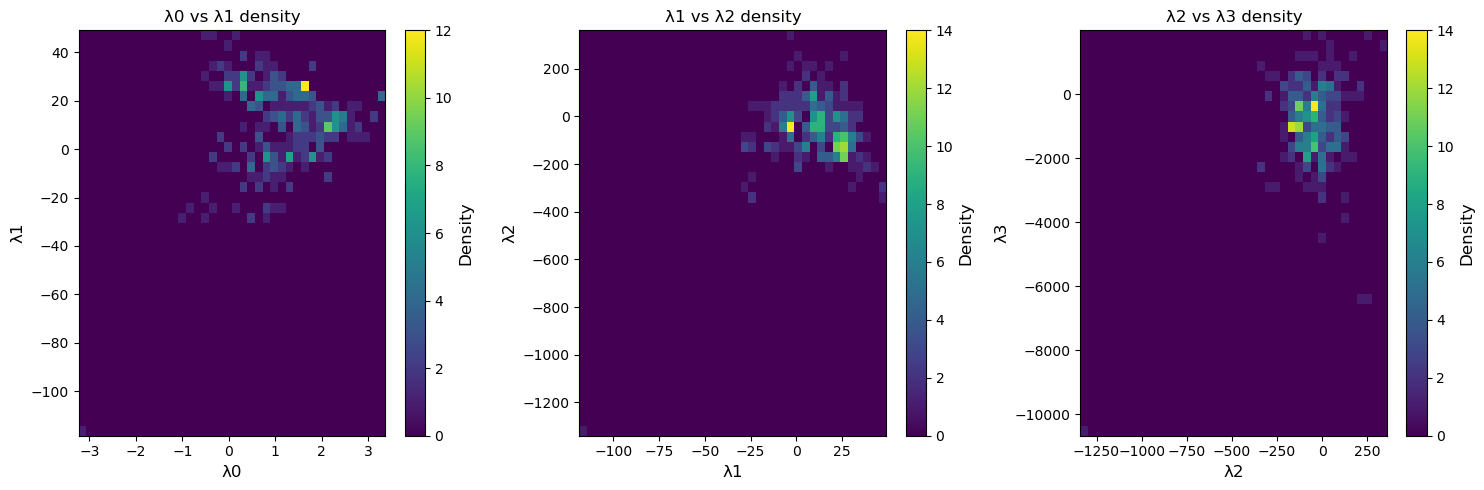

In [38]:
pairs = [
    ("λ0","λ1"),
    ("λ1","λ2"),
    ("λ2","λ3")
]

fig, axes = plt.subplots(1, len(pairs), figsize=(15,5))

for ax, (xcol, ycol) in zip(axes, pairs):

    x = df_model_filt[xcol].to_numpy(float)
    y = df_model_filt[ycol].to_numpy(float)

    m = np.isfinite(x) & np.isfinite(y)
    x = x[m]
    y = y[m]

    # 2D density histogram
    h = ax.hist2d(
        x,
        y,
        bins=40,
        cmap="viridis"
    )

    plt.colorbar(h[3], ax=ax, label="Density")

    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.set_title(f"{xcol} vs {ycol} density")

plt.tight_layout()
plt.show()

#### Interpreting the λ-space density panels

- **Bright core**: the most common REE-pattern “type” in the dataset.
- **Elongated clouds**: continuous mixing/trends (covariation).
- **Multiple peaks**: potential sub-populations.


### Smoothed density + temperature overlay (KDE)

This cell replaces histogram binning with a **kernel density estimate (KDE)**, then overlays the individual points coloured by temperature.
- KDE provides a smoother view of density structure (less sensitive to bin choices),
- temperature colouring can reveal gradients across λ-space that are hard to see in raw scatter,
- robust percentile-based axis limits prevent a few outliers from flattening the central structure.


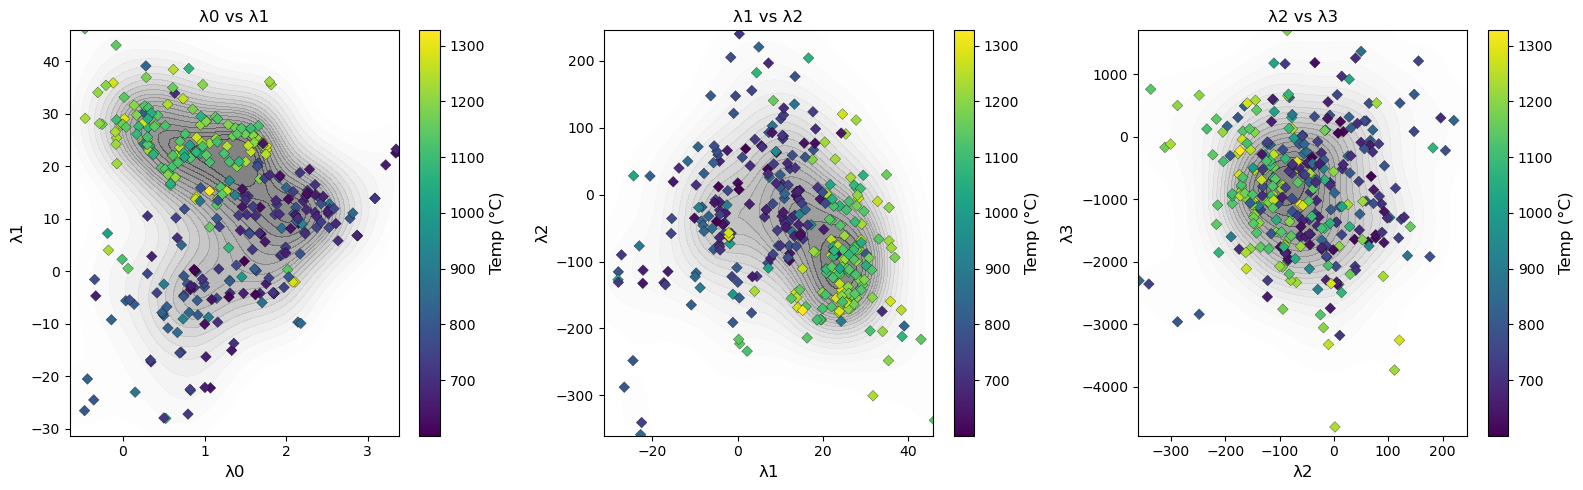

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pairs = [
    ("λ0","λ1"),
    ("λ1","λ2"),
    ("λ2","λ3")
]

temp_col = "Temp (Celc)"

def robust_limits(x, lo=0.01, hi=0.99, pad=0.05):
    """Compute robust axis limits ignoring extreme outliers."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    q_lo, q_hi = np.quantile(x, [lo, hi])
    span = q_hi - q_lo
    return q_lo - pad*span, q_hi + pad*span

fig, axes = plt.subplots(1, len(pairs), figsize=(16,5))

for ax, (xcol, ycol) in zip(axes, pairs):

    x = df_model_filt[xcol].to_numpy(float)
    y = df_model_filt[ycol].to_numpy(float)

    m = np.isfinite(x) & np.isfinite(y)

    if temp_col in df_model_filt.columns:
        temp = df_model_filt[temp_col].to_numpy(float)
        m = m & np.isfinite(temp)
        temp = temp[m]

    x = x[m]
    y = y[m]

    # KDE density
    sns.kdeplot(
        x=x,
        y=y,
        fill=True,
        levels=20,
        cmap="Greys",
        alpha=0.5,
        ax=ax
    )

    # Scatter points coloured by temperature
    if temp_col in df_model_filt.columns:
        sc = ax.scatter(
            x,
            y,
            c=temp,
            cmap="viridis",
            s=30,
            edgecolor="k",
            linewidth=0.2
        )

        plt.colorbar(sc, ax=ax, label="Temp (°C)")
    else:
        ax.scatter(x, y, s=20)

    # Apply robust centering
    ax.set_xlim(*robust_limits(x))
    ax.set_ylim(*robust_limits(y))

    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.set_title(f"{xcol} vs {ycol}")

plt.tight_layout()
plt.show()

#### Interpreting the KDE + temperature overlay

The grey contours show the smoothed density structure; the coloured points show where temperature sits within that structure.
- a monotonic temperature gradient across a density ridge suggests a systematic thermodynamic control,
- temperature “patchiness” suggests multiple processes producing similar λ signatures,
- outliers can be evaluated in the context of both density and fit quality (from earlier diagnostics).


## 9. Cross-check against pyrolite 

### Compute λ0–λ4 using both methods and compare

- **Custom** λ fitting via `lambda_lnREE(...)` (degree 4, Eu included, partial-fit capable).
- **pyrolite** λ fitting via `df.pyrochem.lambda_lnREE(algorithm="ONeill")`.

The joined `comparison` table contains:
- custom λ values (`λ*_custom`),
- pyrolite λ values (`λ*_pyro`),
- differences $Delta\lambda = \lambda_\text{custom} - \lambda_\text{pyro}$.

- agreement increases confidence in thismodel
- systematic offsets highlight differences in assumptions (e.g., handling of missing values, normalisation details, degree selection).


In [41]:
import pyrolite.plot 
sample_col = "SAMPLE NO."

# -------------------------
# 9.1 Custom lambdas (degree=4, keep Eu, allow partial fits handled inside lambda_lnREE)
# -------------------------
custom_rows = []

for i, row in df_analysis.iterrows():
    sample = row[REE].to_numpy(dtype=float)

    try:
        out = lambda_lnREE(sample, degree=4, exclude=(), s_lnREE_percent=2.0)

        custom_rows.append({
            "row_id": i,
            sample_col: row.get(sample_col, np.nan),
            "λ0_custom": out["lambdas"][0],
            "λ1_custom": out["lambdas"][1],
            "λ2_custom": out["lambdas"][2],
            "λ3_custom": out["lambdas"][3],
            "λ4_custom": out["lambdas"][4],
            "n_used_custom": out.get("n_used", np.nan),
            "red_chi_sq_custom": out.get("red_chi_sq", np.nan),
        })
    except Exception:
        continue

custom_df = pd.DataFrame(custom_rows).set_index("row_id").sort_index()


# -------------------------
# 9.2 Pyrolite lambdas (force degree=4 so λ4 is included)
# -------------------------
df_ree_only = df_analysis[REE].copy()

# IMPORTANT: request degree=4 and keep Eu (exclude=[])
# Depending on your pyrolite version, the keyword might be `degree=` or `params={"degree":4}`.
# Most recent versions accept degree= directly.
try:
    lp = df_ree_only.pyrochem.lambda_lnREE(algorithm="ONeill", degree=4, exclude=[]).copy()
except TypeError:
    # fallback for versions which don't expose degree/exclude in signature
    lp = df_ree_only.pyrochem.lambda_lnREE(algorithm="ONeill").copy()

# Attach row_id and sample id for traceability
lp["row_id"] = df_analysis.index.to_numpy()
if sample_col in df_analysis.columns:
    lp[sample_col] = df_analysis[sample_col].to_numpy()

lp = lp.set_index("row_id").sort_index()


# -------------------------
# 9.3 Standardise pyrolite column names to λ0..λ4
# -------------------------
rename_map = {
    "lambda0": "λ0", "lambda1": "λ1", "lambda2": "λ2", "lambda3": "λ3", "lambda4": "λ4",
    "Λ0": "λ0", "Λ1": "λ1", "Λ2": "λ2", "Λ3": "λ3", "Λ4": "λ4",
    0: "λ0", 1: "λ1", 2: "λ2", 3: "λ3", 4: "λ4",
}
lp = lp.rename(columns={k: v for k, v in rename_map.items() if k in lp.columns})

pyro_lams = [c for c in ["λ0","λ1","λ2","λ3","λ4"] if c in lp.columns]
print("Pyrolite lambdas returned:", pyro_lams)

if "λ4" not in pyro_lams:
    print("NOTE: pyrolite did not return λ4. This usually means your call didn't run with degree=4,")
    print("or your pyrolite version doesn't expose degree=4 for this algorithm.")


# -------------------------
# 9.4 Align + compare (only keep λ columns to avoid join overlap)
# -------------------------
lp_keep = lp[pyro_lams].copy()
lp_keep = lp_keep.rename(columns={c: f"{c}_pyro" for c in pyro_lams})

comparison = custom_df.join(lp_keep, how="inner")

# Differences (only for lambdas that pyrolite returned)
for c in pyro_lams:
    comparison[f"Δ{c}"] = comparison[f"{c}_custom"] - comparison[f"{c}_pyro"]

print("comparison shape:", comparison.shape)
display(comparison.head())


# -------------------------
# 9.5 Summary stats
# -------------------------
diff_cols = [f"Δ{c}" for c in pyro_lams]

print("\nMax abs diff:")
print(comparison[diff_cols].abs().max().sort_values(ascending=False))

print("\nMedian abs diff:")
print(comparison[diff_cols].abs().median().sort_values(ascending=False))

print("\nRows compared:", len(comparison))

Pyrolite lambdas returned: ['λ0', 'λ1', 'λ2', 'λ3']
NOTE: pyrolite did not return λ4. This usually means your call didn't run with degree=4,
or your pyrolite version doesn't expose degree=4 for this algorithm.
comparison shape: (580, 16)


,SAMPLE NO.,λ0_custom,λ1_custom,λ2_custom,λ3_custom,λ4_custom,n_used_custom,red_chi_sq_custom,λ0_pyro,λ1_pyro,λ2_pyro,λ3_pyro,Δλ0,Δλ1,Δλ2,Δλ3
row_id,,,,,,,,,,,,,,,,
0,MT.L C5R5 R,1.706819,24.540636,-146.699919,-1036.599851,-1477.126952,14,6.568716,1.767423,24.668094,-147.281289,-1035.143407,-0.060604,-0.127458,0.581370,-1.456444
1,MT.L C5R5 C,1.713648,24.465402,-142.671096,-1122.987912,-1818.697288,14,31.587053,1.773067,24.589390,-143.237076,-1121.188715,-0.059420,-0.123988,0.565980,-1.799196
2,MT.L C8R1 R,1.758205,23.145501,-154.678605,-955.623702,4507.222824,14,28.640907,1.823783,23.291701,-156.925529,-960.172316,-0.065579,-0.146201,2.246923,4.548613
3,MT.L C3R2 C,1.817215,35.527246,-69.060561,-2331.086472,-2839.556580,14,9.772623,1.867716,35.596165,-70.506162,-2328.262884,-0.050501,-0.068919,1.445602,-2.823588
4,MT.L C3R3 C,1.221765,34.630031,-131.928644,-1078.270482,-13528.512926,12,52.917390,1.334146,33.466752,-101.957537,-1559.853320,-0.112382,1.163279,-29.971108,481.582838



Max abs diff:
Δλ3    85937.099612
Δλ2     9739.565706
Δλ1      751.663445
Δλ0       31.250707
dtype: float64

Median abs diff:
Δλ3    12.711963
Δλ2     3.541114
Δλ1     0.116703
Δλ0     0.036411
dtype: float64

Rows compared: 580


#### Interpreting the custom vs pyrolite comparison

The `Δλ` columns quantify agreement term-by-term. In many cases:

- small median |Δλ| indicates the two implementations are effectively equivalent for the dataset,
- larger differences often concentrate in higher-order terms (λ3–λ4), which are more sensitive to missing REEs and fine-scale pattern structure.

If systematic offsets appear (consistent sign across many samples), they usually point to a definitional difference (e.g., degree used, normalisation/transform details, or how missing values are handled).


### 1:1 validation plots (pyrolite vs custom)

This cell produces side-by-side 1:1 plots for λ0–λ4.
- perfect agreement lies on the **1:1 line** $y=x$,
- scatter around the line reflects numerical/assumption differences and/or sensitivity to missing data,
- bias (systematic offset) would appear as a shift away from the line,
- increased spread for higher-order terms (λ3–λ4) can be expected because they are more sensitive to fine-scale pattern features and missing elements.


Lambdas available for plotting: ['λ0', 'λ1', 'λ2', 'λ3']


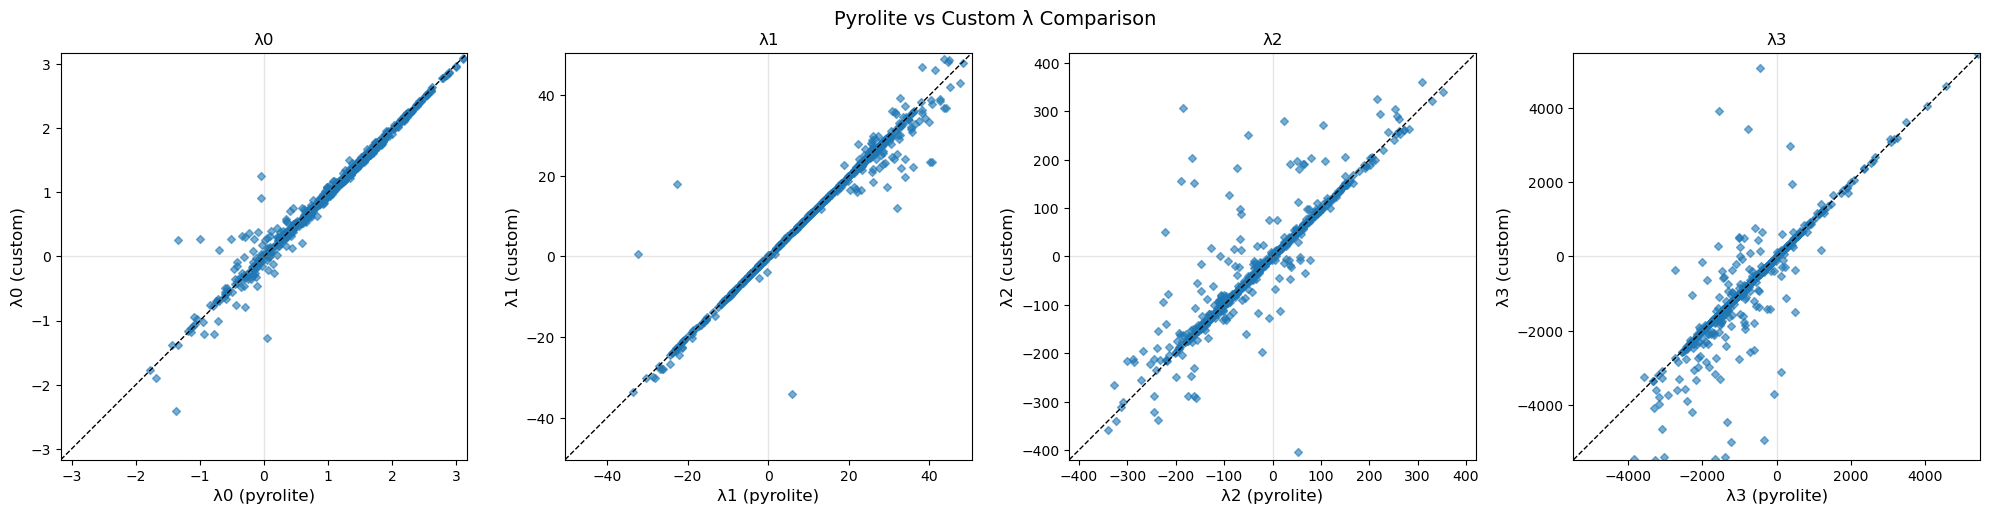

In [42]:
def centred_limits(x, y, lo=0.01, hi=0.99, centre=0.0):
    """Robust symmetric limits centred around centre."""
    v = np.concatenate([x, y])
    v = v[np.isfinite(v)]

    if v.size == 0:
        return (-1, 1)

    q_lo, q_hi = np.quantile(v, [lo, hi])
    span = max(abs(q_lo - centre), abs(q_hi - centre))
    if span == 0:
        span = 1.0

    return (centre - span, centre + span)


# explicitly check which lambdas exist
all_lams = ["λ0","λ1","λ2","λ3","λ4"]
plot_lams = [c for c in all_lams if f"{c}_pyro" in comparison.columns and f"{c}_custom" in comparison.columns]

print("Lambdas available for plotting:", plot_lams)

n = len(plot_lams)

fig, axes = plt.subplots(1, n, figsize=(5*n, 5))

if n == 1:
    axes = [axes]

for ax, c in zip(axes, plot_lams):

    x = comparison[f"{c}_pyro"].to_numpy(float)
    y = comparison[f"{c}_custom"].to_numpy(float)

    m = np.isfinite(x) & np.isfinite(y)
    x = x[m]
    y = y[m]

    ax.scatter(x, y, alpha=0.6)

    lo, hi = centred_limits(x, y)

    # 1:1 line
    ax.plot([lo, hi], [lo, hi], "k--")

    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)

    ax.set_aspect("equal", adjustable="box")

    ax.axhline(0, color="grey", alpha=0.2)
    ax.axvline(0, color="grey", alpha=0.2)

    ax.set_xlabel(f"{c} (pyrolite)")
    ax.set_ylabel(f"{c} (custom)")
    ax.set_title(c)

plt.suptitle("Pyrolite vs Custom λ Comparison", fontsize=14)
plt.tight_layout()
plt.show()


#### Interpreting the 1:1 plots

Ideal behaviour:
- points lie tightly around the 1:1 line for λ0–λ2,
- increasing scatter for λ3–λ4 can be normal (more sensitive terms).

Non-ideal behaviour:
- a slope different from 1 (scaling difference),
- a constant offset (bias),
- fan-shaped scatter (heteroscedasticity, often linked to missing data or varying n_used).


## 10. 3D structure and dimensionality reduction

### 3D λ-space visualisation (two complementary triplets)

This cell plots two 3D λ subspaces:

- **λ0–λ1–λ2**: enrichment, slope, and curvature (often captures the dominant pattern shape variation).
- **λ1–λ2–λ3**: focuses on how curvature relates to higher-order inflections.

Colouring by temperature (when available) provides a first-pass check for thermodynamic/systematic gradients across parameter space.

Robust axis limits are used to keep the central cloud readable in the presence of a few extreme points.


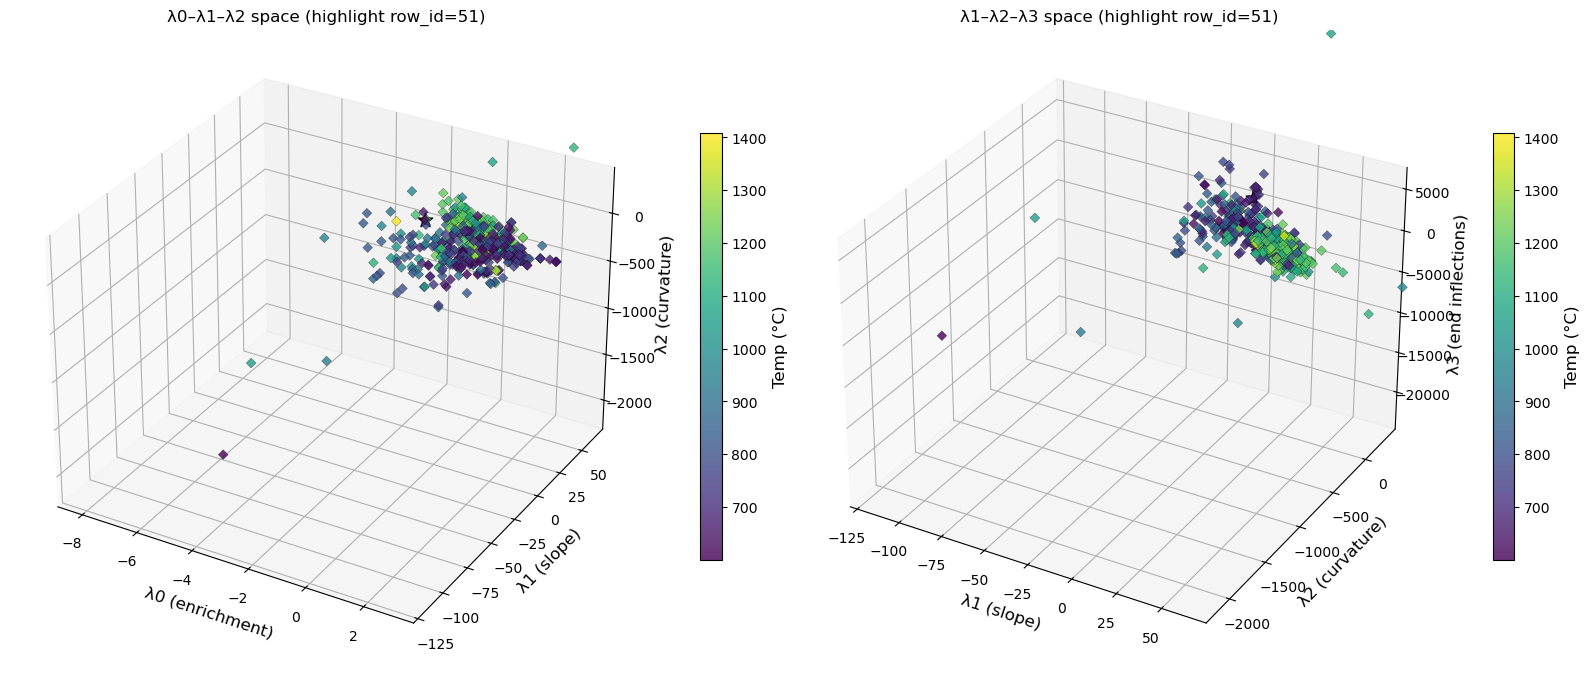

What these 3D plots show:
- Each point is one xenolith clinopyroxene sample in lambda space.
- Left: λ0–λ1–λ2 captures overall enrichment + slope + curvature.
- Right: λ1–λ2–λ3 shows how curvature relates to end-inflections.
- Colour (if present) shows temperature; robust axis limits stop outliers flattening the cloud.
- The star is one random sample (useful for orienting yourself).


In [43]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

# ---- Choose which dataframe holds your lambdas ----
# Use df_model if that's what you're using now.
df_plot = df_model.copy()   # or: df_plot = df_lambdas.copy()

# ---- Optional: drop a known-bad outlier row index (e.g., 162) ----
# If your df_plot index is the original row_id, this will work.
bad_ids = [162]
df_plot = df_plot.drop(index=[i for i in bad_ids if i in df_plot.index], errors="ignore")

# ---- Pick temperature column if present ----
temp_col = "Temp (Celc)"
has_temp = temp_col in df_plot.columns
temp_vals = df_plot[temp_col].to_numpy(float) if has_temp else None
temp_ok = np.isfinite(temp_vals) if has_temp else None

# ---- Filter to finite lambda rows for each plot (prevents weird 3D errors) ----
def finite_mask(cols):
    arr = df_plot[cols].to_numpy(float)
    return np.isfinite(arr).all(axis=1)

m012 = finite_mask(["λ0", "λ1", "λ2"])
m123 = finite_mask(["λ1", "λ2", "λ3"])

# ---- Robust axis limits helper (so your cloud isn't flattened by a few extremes) ----
def robust_limits_1d(x, lo=0.01, hi=0.99, pad=0.05):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return (-1, 1)
    a, b = np.quantile(x, [lo, hi])
    span = b - a
    if span == 0:
        span = 1.0
    return (a - pad * span, b + pad * span)

# ---- Optional: highlight a random sample (from the valid set) ----
rng = np.random.default_rng(42)
highlight_idx = None
if m012.any():
    highlight_idx = df_plot.index.to_numpy()[rng.choice(np.where(m012)[0])]

# ---- Figure setup ----
fig = plt.figure(figsize=(16, 7))
ax1 = fig.add_subplot(121, projection="3d")
ax2 = fig.add_subplot(122, projection="3d")

# ---- Style ----
pts_style = dict(s=25, alpha=0.8, edgecolor="k", linewidth=0.2)

# =========================
# Panel 1: λ0–λ1–λ2
# =========================
x = df_plot.loc[m012, "λ0"].to_numpy(float)
y = df_plot.loc[m012, "λ1"].to_numpy(float)
z = df_plot.loc[m012, "λ2"].to_numpy(float)

if has_temp:
    c = temp_vals[m012 & temp_ok]
    # To keep arrays aligned, use a mask that requires both lambdas + temp finite
    mt = m012 & temp_ok
    sc1 = ax1.scatter(
        df_plot.loc[mt, "λ0"].to_numpy(float),
        df_plot.loc[mt, "λ1"].to_numpy(float),
        df_plot.loc[mt, "λ2"].to_numpy(float),
        c=temp_vals[mt],
        **pts_style
    )
    cb1 = plt.colorbar(sc1, ax=ax1, fraction=0.03, pad=0.08)
    cb1.set_label("Temp (°C)")
else:
    ax1.scatter(x, y, z, **pts_style)

# Highlight point (optional)
if highlight_idx is not None and highlight_idx in df_plot.index:
    ax1.scatter(
        df_plot.loc[highlight_idx, "λ0"],
        df_plot.loc[highlight_idx, "λ1"],
        df_plot.loc[highlight_idx, "λ2"],
        s=120, marker="*", edgecolor="k"
    )
    ax1.set_title(f"λ0–λ1–λ2 space (highlight row_id={highlight_idx})")
else:
    ax1.set_title("λ0–λ1–λ2 space")

ax1.set_xlabel("λ0 (enrichment)")
ax1.set_ylabel("λ1 (slope)")
ax1.set_zlabel("λ2 (curvature)")

# Robust limits for nicer framing
ax1.set_xlim(*robust_limits_1d(x))
ax1.set_ylim(*robust_limits_1d(y))
ax1.set_zlim(*robust_limits_1d(z))

# =========================
# Panel 2: λ1–λ2–λ3
# =========================
x = df_plot.loc[m123, "λ1"].to_numpy(float)
y = df_plot.loc[m123, "λ2"].to_numpy(float)
z = df_plot.loc[m123, "λ3"].to_numpy(float)

if has_temp:
    mt = m123 & temp_ok
    sc2 = ax2.scatter(
        df_plot.loc[mt, "λ1"].to_numpy(float),
        df_plot.loc[mt, "λ2"].to_numpy(float),
        df_plot.loc[mt, "λ3"].to_numpy(float),
        c=temp_vals[mt],
        **pts_style
    )
    cb2 = plt.colorbar(sc2, ax=ax2, fraction=0.03, pad=0.08)
    cb2.set_label("Temp (°C)")
else:
    ax2.scatter(x, y, z, **pts_style)

# Optional: same highlight if it exists for these axes too
if highlight_idx is not None and highlight_idx in df_plot.index and np.isfinite(df_plot.loc[highlight_idx, ["λ1","λ2","λ3"]].to_numpy(float)).all():
    ax2.scatter(
        df_plot.loc[highlight_idx, "λ1"],
        df_plot.loc[highlight_idx, "λ2"],
        df_plot.loc[highlight_idx, "λ3"],
        s=120, marker="*", edgecolor="k"
    )
    ax2.set_title(f"λ1–λ2–λ3 space (highlight row_id={highlight_idx})")
else:
    ax2.set_title("λ1–λ2–λ3 space")

ax2.set_xlabel("λ1 (slope)")
ax2.set_ylabel("λ2 (curvature)")
ax2.set_zlabel("λ3 (end inflections)")

ax2.set_xlim(*robust_limits_1d(x))
ax2.set_ylim(*robust_limits_1d(y))
ax2.set_zlim(*robust_limits_1d(z))

plt.tight_layout()
plt.show()

print(
    "What these 3D plots show:\n"
    "- Each point is one xenolith clinopyroxene sample in lambda space.\n"
    "- Left: λ0–λ1–λ2 captures overall enrichment + slope + curvature.\n"
    "- Right: λ1–λ2–λ3 shows how curvature relates to end-inflections.\n"
    "- Colour (if present) shows temperature; robust axis limits stop outliers flattening the cloud.\n"
    "- The star is one random sample (useful for orienting yourself)."
)

### PCA-based tilted-plane slice (trend-aligned slicing)

This cell uses PCA (via SVD) to find the main trend direction (**PC1**) in a chosen 3D λ space, then defines a **tilted slicing plane**:

- the plane normal is aligned with PC1,
- the plane passes through the robust centre (median),
- samples are ranked by projection onto the normal direction.

A “slice” is defined as the upper quantile (e.g., top 10%) along that projection.
- it selects samples that are extreme **along the dominant multivariate trend**, not just extreme in one λ coordinate,
- it makes it easier to compare “core cloud” vs “trend-end” samples in downstream interpretation or mapping back to sample metadata.


Using 547 points in space ['λ0', 'λ1', 'λ2'] (temp=yes)
Tilted plane: normal ≈ PC1, slice is proj >= 0.90 quantile
Slice size: 55 / 547


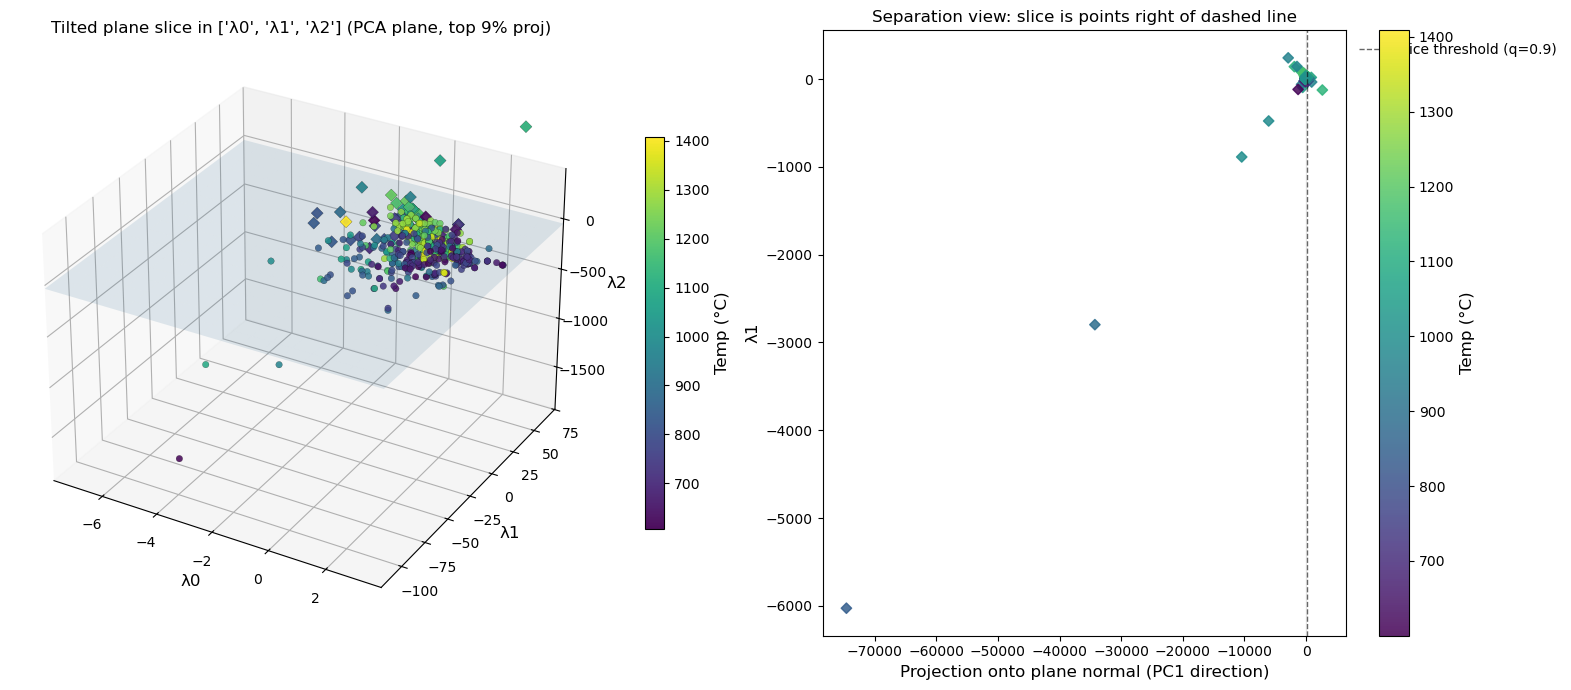

What this does:
- Finds the main trend direction (PC1) in your chosen 3D lambda space.
- Builds a *tilted plane* perpendicular to that trend and passing through the cloud centre.
- Defines a slice as the top quantile along that PC1 direction.
- Left plot shows the plane + slice points; right plot shows a clean separation along projection.



In [44]:
# ------------------------------------------------------------
# 0) Choose which 3D lambda space you want to slice
# ------------------------------------------------------------
df_plot = df_model.copy()
df_plot = df_plot.drop(index=[162], errors="ignore")  # drop known bad outlier

space_cols = ["λ0", "λ1", "λ2"]   # <-- change to ["λ1","λ2","λ3"] or any 3 lambdas
temp_col = "Temp (Celc)"
q_slice = 0.90                   # top 10% on +side of the plane

# ------------------------------------------------------------
# 1) Build a clean matrix for this space (+ optional temp)
# ------------------------------------------------------------
X = df_plot[space_cols].to_numpy(float)
m = np.isfinite(X).all(axis=1)

has_temp = temp_col in df_plot.columns
if has_temp:
    T = df_plot[temp_col].to_numpy(float)
    m = m & np.isfinite(T)
else:
    T = None

X = df_plot.loc[m, space_cols].to_numpy(float)
idx = df_plot.index.to_numpy()[m]
if has_temp:
    T = df_plot.loc[m, temp_col].to_numpy(float)

print(f"Using {len(X)} points in space {space_cols} (temp={'yes' if has_temp else 'no'})")

# ------------------------------------------------------------
# 2) PCA: get a tilted slicing plane
# Plane normal = PC1 (main trend)
# Plane passes through robust centre (median point)
# ------------------------------------------------------------
centre = np.median(X, axis=0)
Xc = X - centre

# SVD gives principal directions robustly
# Vt[0] is PC1 direction in feature space
_, _, Vt = np.linalg.svd(Xc, full_matrices=False)
normal = Vt[0]                  # plane normal (tilted)
normal = normal / np.linalg.norm(normal)

# Signed projection onto normal (distance along PC1)
proj = Xc @ normal              # scalar per point

# Define slice threshold by quantile along proj
thr = np.quantile(proj, q_slice)
side = proj >= thr              # "high-PC1 side" slice

print(f"Tilted plane: normal ≈ PC1, slice is proj >= {q_slice:.2f} quantile")
print(f"Slice size: {side.sum()} / {len(side)}")

# ------------------------------------------------------------
# 3) Robust axis limits helper
# ------------------------------------------------------------
def robust_limits_1d(x, lo=0.01, hi=0.99, pad=0.08):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return (-1, 1)
    a, b = np.quantile(x, [lo, hi])
    span = b - a
    if span == 0:
        span = 1.0
    return (a - pad * span, b + pad * span)

xl = robust_limits_1d(X[:, 0])
yl = robust_limits_1d(X[:, 1])
zl = robust_limits_1d(X[:, 2])

# ------------------------------------------------------------
# 4) Build a plane patch for plotting
# We create a grid in (x,y) and solve for z using:
# normal · ([x,y,z] - centre) = 0  =>  z = cz - (nx(x-cx)+ny(y-cy))/nz
# If nz is tiny (plane nearly vertical), we switch to solving for y instead.
# ------------------------------------------------------------
nx, ny, nz = normal
cx, cy, cz = centre

grid_n = 18
xx, yy = np.meshgrid(np.linspace(xl[0], xl[1], grid_n),
                     np.linspace(yl[0], yl[1], grid_n))

if abs(nz) > 1e-8:
    zz = cz - (nx * (xx - cx) + ny * (yy - cy)) / nz
    plane_mode = "solve_z"
else:
    # fallback: solve for y if nz ~ 0
    # ny(y-cy) = -(nx(x-cx) + nz(z-cz)) -> y = cy - (nx(x-cx) + nz(z-cz))/ny
    zz = np.meshgrid(np.linspace(zl[0], zl[1], grid_n),
                     np.linspace(zl[0], zl[1], grid_n))[0]
    if abs(ny) < 1e-8:
        # extremely degenerate; just skip plane
        zz = None
        plane_mode = "skip"
    else:
        yy = cy - (nx * (xx - cx) + nz * (zz - cz)) / ny
        plane_mode = "solve_y"

# ------------------------------------------------------------
# 5) Two-panel figure:
# Left: 3D cloud + tilted plane + highlighted slice
# Right: separation plot using signed distance/projection
# ------------------------------------------------------------
fig = plt.figure(figsize=(16, 7))
ax3d = fig.add_subplot(121, projection="3d")

# faint full cloud
ax3d.scatter(X[:, 0], X[:, 1], X[:, 2], s=12, alpha=0.12, color="grey", edgecolor="none")

# plot the tilted plane
if zz is not None and plane_mode != "skip":
    ax3d.plot_surface(xx, yy, zz, alpha=0.12)

# plot slice points vs non-slice points
pts_style = dict(edgecolor="k", linewidth=0.15)
if has_temp:
    # non-slice: circles; slice: diamonds (both temp-coloured)
    sc0 = ax3d.scatter(X[~side, 0], X[~side, 1], X[~side, 2],
                       c=T[~side], s=22, alpha=0.85, marker="o", **pts_style)
    sc1 = ax3d.scatter(X[side, 0], X[side, 1], X[side, 2],
                       c=T[side], s=38, alpha=0.95, marker="D", **pts_style)
    cb = plt.colorbar(sc1, ax=ax3d, fraction=0.03, pad=0.08)
    cb.set_label("Temp (°C)")
else:
    ax3d.scatter(X[~side, 0], X[~side, 1], X[~side, 2],
                 s=22, alpha=0.85, marker="o", color="steelblue", **pts_style)
    ax3d.scatter(X[side, 0], X[side, 1], X[side, 2],
                 s=38, alpha=0.95, marker="D", color="crimson", **pts_style)

ax3d.set_xlabel(space_cols[0])
ax3d.set_ylabel(space_cols[1])
ax3d.set_zlabel(space_cols[2])
ax3d.set_title(f"Tilted plane slice in {space_cols} (PCA plane, top {int((1-q_slice)*100)}% proj)")
ax3d.set_xlim(*xl); ax3d.set_ylim(*yl); ax3d.set_zlim(*zl)

# ---- Right panel: distance-to-plane separation ----
ax2 = fig.add_subplot(122)

# proj is along plane normal; dist-to-plane (signed) for the plane through centre is just proj
# Here we show a clean separation: proj on x-axis, and one lambda on y for context
y_show = X[:, 1]  # show the middle axis against projection
if has_temp:
    sc = ax2.scatter(proj, y_show, c=T, s=28, alpha=0.85)
    cb2 = plt.colorbar(sc, ax=ax2)
    cb2.set_label("Temp (°C)")
else:
    sc = ax2.scatter(proj, y_show, s=28, alpha=0.85)

ax2.axvline(thr, color="k", linestyle="--", alpha=0.6, label=f"slice threshold (q={q_slice})")
ax2.axvline(0, color="grey", alpha=0.2)

ax2.set_xlabel("Projection onto plane normal (PC1 direction)")
ax2.set_ylabel(space_cols[1])
ax2.set_title("Separation view: slice is points right of dashed line")
ax2.legend()

plt.tight_layout()
plt.show()

print(
    "What this does:\n"
    "- Finds the main trend direction (PC1) in your chosen 3D lambda space.\n"
    "- Builds a *tilted plane* perpendicular to that trend and passing through the cloud centre.\n"
    "- Defines a slice as the top quantile along that PC1 direction.\n"
    "- Left plot shows the plane + slice points; right plot shows a clean separation along projection.\n"
)

## Notes 
- Add tetrad effect calculations
- what uncertainty number to use? current at 2%